#Exploratory Data Analysis

Dataset Source: https://www.kaggle.com/datasets/ermila/klasifikasi-tingkat-kemiskinan-di-indonesia?resource=download

Initializing Dataset

In [16]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
df = pd.read_csv("Poverty.csv", sep=";")

display(df.head())

,Provinsi,Kab/Kota,Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),Rata-rata Lama Sekolah Penduduk 15+ (Tahun),Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),Indeks Pembangunan Manusia,Umur Harapan Hidup (Tahun),Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,Persentase rumah tangga yang memiliki akses terhadap air minum layak,Tingkat Pengangguran Terbuka,Tingkat Partisipasi Angkatan Kerja,PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),Klasifikasi Kemiskinan
0,ACEH,Simeulue,18.98,9.48,7148,66.41,65.28,71.56,87.45,5.71,71.15,1648096,0
1,ACEH,Aceh Singkil,20.36,8.68,8776,69.22,67.43,69.56,78.58,8.36,62.85,1780419,1
2,ACEH,Aceh Selatan,13.18,8.88,8180,67.44,64.40,62.55,79.65,6.46,60.85,4345784,0
3,ACEH,Aceh Tenggara,13.41,9.67,8030,69.44,68.22,62.71,86.71,6.43,69.62,3487157,0
4,ACEH,Aceh Timur,14.45,8.21,8577,67.83,68.74,66.75,83.16,7.13,59.48,8433526,0


In [18]:
print("Dataset dimensions:", df.shape)

Dataset dimensions: (514, 13)


Descriptive Statistic

In [44]:
df.describe().round(2)

,Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),Rata-rata Lama Sekolah Penduduk 15+ (Tahun),Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),Indeks Pembangunan Manusia,Umur Harapan Hidup (Tahun),Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,Persentase rumah tangga yang memiliki akses terhadap air minum layak,Tingkat Pengangguran Terbuka,Tingkat Partisipasi Angkatan Kerja,PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),Klasifikasi Kemiskinan,Poverty_Status
count,514.00,514.00,514.00,514.00,514.00,514.00,514.00,514.00,514.00,5.140000e+02,514.00,514.00
mean,12.27,8.44,10324.79,69.93,69.66,77.20,85.14,5.06,69.46,2.196408e+07,0.12,0.54
std,7.46,1.63,2717.14,6.50,3.45,18.58,15.70,2.64,6.40,4.790492e+07,0.33,0.50
min,2.38,1.42,3976.00,32.84,55.43,0.00,0.00,0.00,56.39,1.474850e+05,0.00,0.00
25%,7.15,7.51,8574.00,66.64,67.39,70.22,79.04,3.18,65.07,3.654292e+06,0.00,0.00
50%,10.46,8.30,10196.50,69.61,69.97,81.80,89.79,4.56,68.96,8.814926e+06,0.00,1.00
75%,14.89,9.34,11719.00,73.11,72.04,89.88,96.40,6.53,72.34,1.973510e+07,0.00,1.00
max,41.66,12.83,23888.00,87.18,77.73,99.97,100.00,13.37,97.93,4.600810e+08,1.00,1.00


P0 mean: 12.273151750972762
P0 median: 10.455
P0 minimum: 2.38
P0 maximum: 41.66


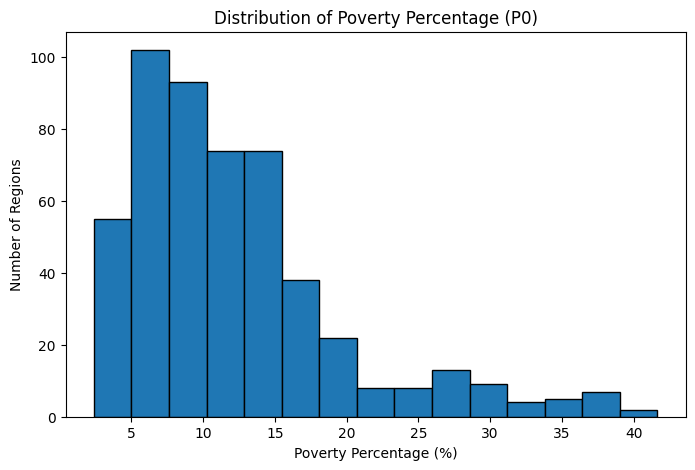

In [20]:
p0 = "Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)"

print("P0 mean:", df[p0].mean())
print("P0 median:", df[p0].median())
print("P0 minimum:", df[p0].min())
print("P0 maximum:", df[p0].max())

plt.figure(figsize=(8, 5))
plt.hist(df[p0], bins=15, edgecolor="black")

plt.title("Distribution of Poverty Percentage (P0)")
plt.xlabel("Poverty Percentage (%)")
plt.ylabel("Number of Regions")

plt.show()

Training and Testing

In [49]:
df["Poverty_Status"] = (df[p0] >= 10).astype(int)

X = df[
    [
        "Indeks Pembangunan Manusia",
        "Persentase rumah tangga yang memiliki akses terhadap sanitasi layak",
        "Tingkat Pengangguran Terbuka",
        "Tingkat Partisipasi Angkatan Kerja"
    ]
]

y = df["Poverty_Status"]

print("Predictors (X):")
print(X.head())

print("\nTarget (Y):")
print(y.head().values)

Predictors (X):
   Indeks Pembangunan Manusia  \
0                       66.41   
1                       69.22   
2                       67.44   
3                       69.44   
4                       67.83   

   Persentase rumah tangga yang memiliki akses terhadap sanitasi layak  \
0                                              71.56                     
1                                              69.56                     
2                                              62.55                     
3                                              62.71                     
4                                              66.75                     

   Tingkat Pengangguran Terbuka  Tingkat Partisipasi Angkatan Kerja  
0                          5.71                               71.15  
1                          8.36                               62.85  
2                          6.46                               60.85  
3                          6.43                             

In [47]:
print("Class distribution:")
print(y.value_counts().round(2).to_string())

print("\nPercentage distribution:")
print((y.value_counts(normalize=True) * 100).round(2).to_string())

Class distribution:
Poverty_Status
1    277
0    237

Percentage distribution:
Poverty_Status
1    53.89
0    46.11


Splitting Training and Testing Data

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().to_string())

print("\nTesting target distribution:")
print(y_test.value_counts().to_string())

Training data: (411, 4)
Testing data: (103, 4)

Training target distribution:
Poverty_Status
1    221
0    190

Testing target distribution:
Poverty_Status
1    56
0    47


Naive Bayes and Logistic Regression

In [50]:
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)
p_nb = nb.predict_proba(X_test)[:, 1]

lr = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)
)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
p_lr = lr.predict_proba(X_test)[:, 1]

print("Naive Bayes predictions:", y_pred_nb[:5], p_nb[:5])
print("Logistic Regression predictions:", y_pred_lr[:5], p_lr[:5])

Naive Bayes predictions: [1 1 0 1 0] [0.60007296 1.         0.36939524 0.64780339 0.44722413]
Logistic Regression predictions: [1 1 0 1 1] [0.60767262 0.99989535 0.46434739 0.62885409 0.61334384]


Accuracy, Precision, Recall, and F1-score

In [51]:
nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_precision = precision_score(y_test, y_pred_nb)
nb_recall = recall_score(y_test, y_pred_nb)
nb_f1 = f1_score(y_test, y_pred_nb)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

comparison = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [nb_accuracy, lr_accuracy],
    "Precision": [nb_precision, lr_precision],
    "Recall": [nb_recall, lr_recall],
    "F1-score": [nb_f1, lr_f1]
})

print(comparison.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score
        Naive Bayes    0.6019     0.6415  0.6071    0.6239
Logistic Regression    0.6893     0.6714  0.8393    0.7460


Confusion Matrix

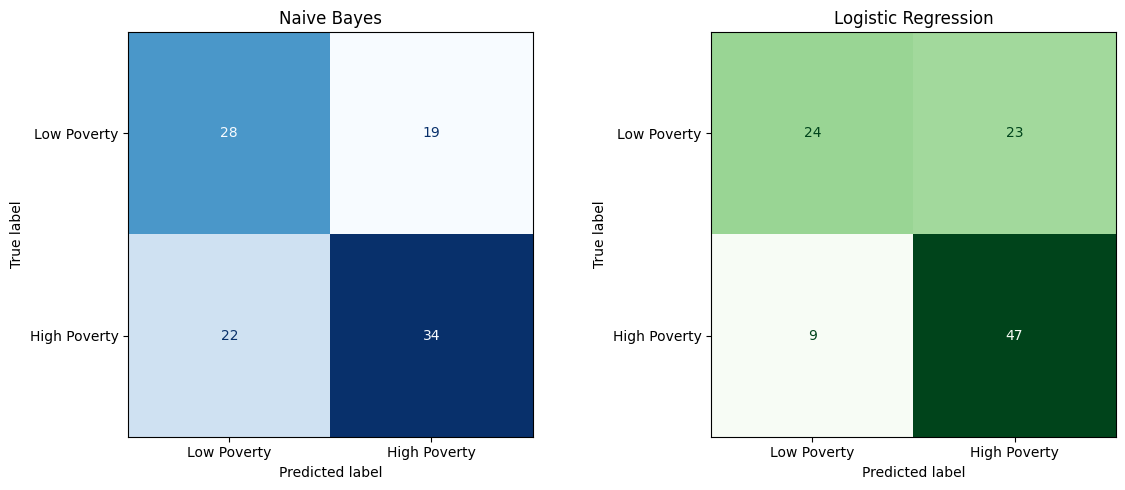

In [28]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

cm_lr = confusion_matrix(y_test, y_pred_lr)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Low Poverty", "High Poverty"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Naive Bayes")

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Low Poverty", "High Poverty"]
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Logistic Regression")

plt.tight_layout()
plt.show()